## Environment

In [3]:
import os, json, time, zipfile, shutil, requests, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import tensorflow as tf
warnings.filterwarnings('ignore')

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow', tf.__version__)
gpus = tf.config.list_physical_devices('GPU'); print('GPUs:', gpus)
if not gpus:
    print('WARNING: no GPU found. Runtime -> Change runtime type -> T4 GPU, then run again.')

from google.colab import drive
drive.mount('/content/drive')
DRIVE_DIR = '/content/drive/MyDrive/SignSense_data'
WORK, PROC = '/content/work', '/content/processed'
OUT = '/content/results'; os.makedirs(WORK, exist_ok=True); os.makedirs(OUT, exist_ok=True)

SMALL = ['processed_metadata.csv', 'dynamic_landmarks.npz', 'label_map.json', 'class_weights.json', 'channel_stats.json', 'channel_stats_train.json']
missing = [f for f in SMALL if not os.path.exists(os.path.join(DRIVE_DIR, f))]
assert not missing, f'Upload these files to {DRIVE_DIR}: {missing}'
for f in SMALL: shutil.copy(os.path.join(DRIVE_DIR, f), WORK)

TensorFlow 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load metadata, label maps, class weights, normalization statistics

In [4]:
meta = pd.read_csv(f'{WORK}/processed_metadata.csv')
imgs = meta[meta['media_type'] == 'image'].reset_index(drop=True)
imgs['is_generated'] = imgs['is_generated'].astype(bool)
dyn = meta[meta['media_type'] == 'video'].reset_index(drop=True)

lm = json.load(open(f'{WORK}/label_map.json'))
label2id, STATIC, DYNAMIC = lm['label2id'], lm['static_classes'], lm['dynamic_classes']
id2label = {v: k for k, v in label2id.items()}
cw = json.load(open(f'{WORK}/class_weights.json'))
static_cw = {int(k): v for k, v in cw['static'].items()}; dyn_cw = {int(k) - len(STATIC): v for k, v in cw['dynamic'].items()}
st = json.load(open(f'{WORK}/channel_stats_train.json'))
MEAN, STD = np.array(st['rgb_mean'], np.float32), np.array(st['rgb_std'], np.float32)

print('Static classes:', len(STATIC), '| dynamic classes:', len(DYNAMIC))
print('Images per split:', imgs['split'].value_counts().to_dict(), '| videos per split:', dyn['split'].value_counts().to_dict())
print('Train RGB mean/std:', MEAN.round(4).tolist(), STD.round(4).tolist())

Static classes: 36 | dynamic classes: 4
Images per split: {'train': 15062, 'test': 3238, 'val': 3060} | videos per split: {'train': 275, 'val': 59, 'test': 59}
Train RGB mean/std: [0.6891999840736389, 0.6248000264167786, 0.6011999845504761] [0.21119999885559082, 0.23000000417232513, 0.24320000410079956]


## 2. Make sure the processed images are available
Order of attempts: already in Colab → unzip from Drive (`processed_images.zip`) → rebuild from the raw dataset using the same padding code as Phase 1 (about 10 minutes), then save the zip to Drive so later sessions are fast.

In [5]:
def processed_ok():
    return os.path.isdir(PROC) and all(os.path.exists(os.path.join(PROC, p)) for p in imgs['processed_path'])

ZIP_DRIVE = f'{DRIVE_DIR}/processed_images.zip'
if not processed_ok() and os.path.exists(ZIP_DRIVE):
    print('Unzipping processed images from Drive...')
    shutil.copy(ZIP_DRIVE, '/content/processed_images.zip')
    with zipfile.ZipFile('/content/processed_images.zip') as z: z.extractall(PROC)

if not processed_ok():
    print('Rebuilding processed images from the raw dataset...')
    DATA_DIR = '/content/data'; ROOT = os.path.join(DATA_DIR, 'Pakistan Sign Language Urdu Alphabets')
    if not os.path.isdir(ROOT):
        URL = 'https://data.mendeley.com/public-api/zip/3pvnnckxyb/download/1'; Z = '/content/ualpha40.zip'
        if not os.path.exists(Z):
            with requests.get(URL, stream=True) as r:
                r.raise_for_status()
                with open(Z, 'wb') as f:
                    for ch in r.iter_content(chunk_size=1 << 20): f.write(ch)
        with zipfile.ZipFile(Z) as zf: zf.extractall(DATA_DIR)
    IMG_SIZE_BUILD = 224
    eda = json.load(open(f'{WORK}/channel_stats.json'))
    fill_bgr = (np.array(eda['rgb_mean']) * 255).round().astype(np.uint8)[::-1].copy()
    def resize_pad(img, size=IMG_SIZE_BUILD, fill=fill_bgr):
        h, w = img.shape[:2]; s = size / max(h, w)
        nh, nw = max(1, round(h * s)), max(1, round(w * s))
        r = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
        canvas = np.empty((size, size, 3), np.uint8); canvas[:] = fill
        top, left = (size - nh) // 2, (size - nw) // 2
        canvas[top:top + nh, left:left + nw] = r
        return canvas
    def build(row):
        dst = os.path.join(PROC, row[1]); os.makedirs(os.path.dirname(dst), exist_ok=True)
        if not os.path.exists(dst):
            cv2.imwrite(dst, resize_pad(cv2.imread(os.path.join(ROOT, row[0]))), [cv2.IMWRITE_JPEG_QUALITY, 95])
    with ThreadPoolExecutor(max_workers=8) as ex:
        list(ex.map(build, zip(imgs['rel_path'], imgs['processed_path'])))
    shutil.make_archive('/content/processed_images', 'zip', PROC)
    os.makedirs(DRIVE_DIR, exist_ok=True); shutil.copy('/content/processed_images.zip', ZIP_DRIVE)
    print('Saved processed_images.zip to Drive for next time.')

assert processed_ok(); print('Processed images ready:', len(imgs))

Rebuilding processed images from the raw dataset...
Saved processed_images.zip to Drive for next time.
Processed images ready: 21360


## 3. Static pipeline (`tf.data`)
- Images are decoded from the processed JPEGs (already 224×224, padded).
- **Augmentation (training only):** small rotation, shift, zoom, contrast and brightness changes. No horizontal flips: they would turn a right hand into a left hand and are not guaranteed to preserve a sign.
- **Normalization modes** (chosen per backbone): `efficientnet` = raw 0–255, `mobilenetv2` = x/127.5 − 1, `dataset` = (x/255 − mean)/std with the training statistics.
- `original_only=True` builds an evaluation set from non-augmented photos only (the most realistic estimate).

In [6]:
IMG_SIZE, BATCH, AUTOTUNE = 224, 64, tf.data.AUTOTUNE
L = tf.keras.layers
augment = tf.keras.Sequential([
    L.RandomRotation(0.03, fill_mode='nearest'),          # +-0.03 * 2pi, about 11 degrees
    L.RandomTranslation(0.05, 0.05, fill_mode='nearest'),
    L.RandomZoom(0.1, fill_mode='nearest'),
    L.RandomContrast(0.15),
    L.RandomBrightness(0.15, value_range=(0, 255)),
], name='augment')

def get_norm(mode):
    if mode == 'efficientnet': return lambda x: x
    if mode == 'mobilenetv2':  return lambda x: x / 127.5 - 1.0
    if mode == 'dataset':      return lambda x: (x / 255.0 - MEAN) / STD
    raise ValueError(mode)

def decode(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.ensure_shape(img, [IMG_SIZE, IMG_SIZE, 3])
    return tf.cast(img, tf.float32), label

def make_static_ds(split, training=False, norm='efficientnet', batch=BATCH, original_only=False):
    d = imgs[imgs['split'] == split]
    if original_only: d = d[~d['is_generated']]
    paths = [os.path.join(PROC, p) for p in d['processed_path']]
    ds = tf.data.Dataset.from_tensor_slices((paths, d['class_id'].values.astype('int32')))
    if training: ds = ds.shuffle(len(d), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode, AUTOTUNE).batch(batch)
    if training: ds = ds.map(lambda x, y: (augment(x, training=True), y), AUTOTUNE)
    nf = get_norm(norm)
    return ds.map(lambda x, y: (nf(x), y), AUTOTUNE).prefetch(AUTOTUNE)

train_ds = make_static_ds('train', training=True)
val_ds   = make_static_ds('val')
test_ds  = make_static_ds('test')
test_orig_ds = make_static_ds('test', original_only=True)
print('Datasets ready. Test set (all):', (imgs['split'] == 'test').sum(), '| test set (originals only):', ((imgs['split'] == 'test') & ~imgs['is_generated']).sum())

Datasets ready. Test set (all): 3238 | test set (originals only): 430


### 3.1 Sanity checks: shapes, value ranges, speed

In [7]:
x, y = next(iter(train_ds))
print('Batch:', x.shape, x.dtype, '| labels:', y.shape, y.dtype, '| label range:', int(y.numpy().min()), '-', int(y.numpy().max()))

for mode in ['efficientnet', 'mobilenetv2', 'dataset']:
    xb, _ = next(iter(make_static_ds('val', norm=mode)))
    print(f'{mode:13s} min={float(tf.reduce_min(xb)):8.3f} max={float(tf.reduce_max(xb)):8.3f} mean={float(tf.reduce_mean(xb)):7.3f} std={float(tf.math.reduce_std(xb)):6.3f}')

# Every class must appear in val and test
for s in ['val', 'test']:
    n_cls = imgs[imgs['split'] == s]['class_id'].nunique(); assert n_cls == len(STATIC), (s, n_cls)
print('OK: all', len(STATIC), 'classes present in val and test')

t0 = time.time(); n = 0
for xb, _ in train_ds.take(20): n += len(xb)
speed = n / (time.time() - t0); print(f'Loading speed (with augmentation): {speed:.0f} images/s')

Batch: (64, 224, 224, 3) <dtype: 'float32'> | labels: (64,) <dtype: 'int32'> | label range: 0 - 35
efficientnet  min=   0.000 max= 255.000 mean=158.192 std=55.035
mobilenetv2   min=  -1.000 max=   1.000 mean=  0.241 std= 0.432
dataset       min=  -3.263 max=   1.640 mean= -0.079 std= 0.932
OK: all 36 classes present in val and test
Loading speed (with augmentation): 62 images/s


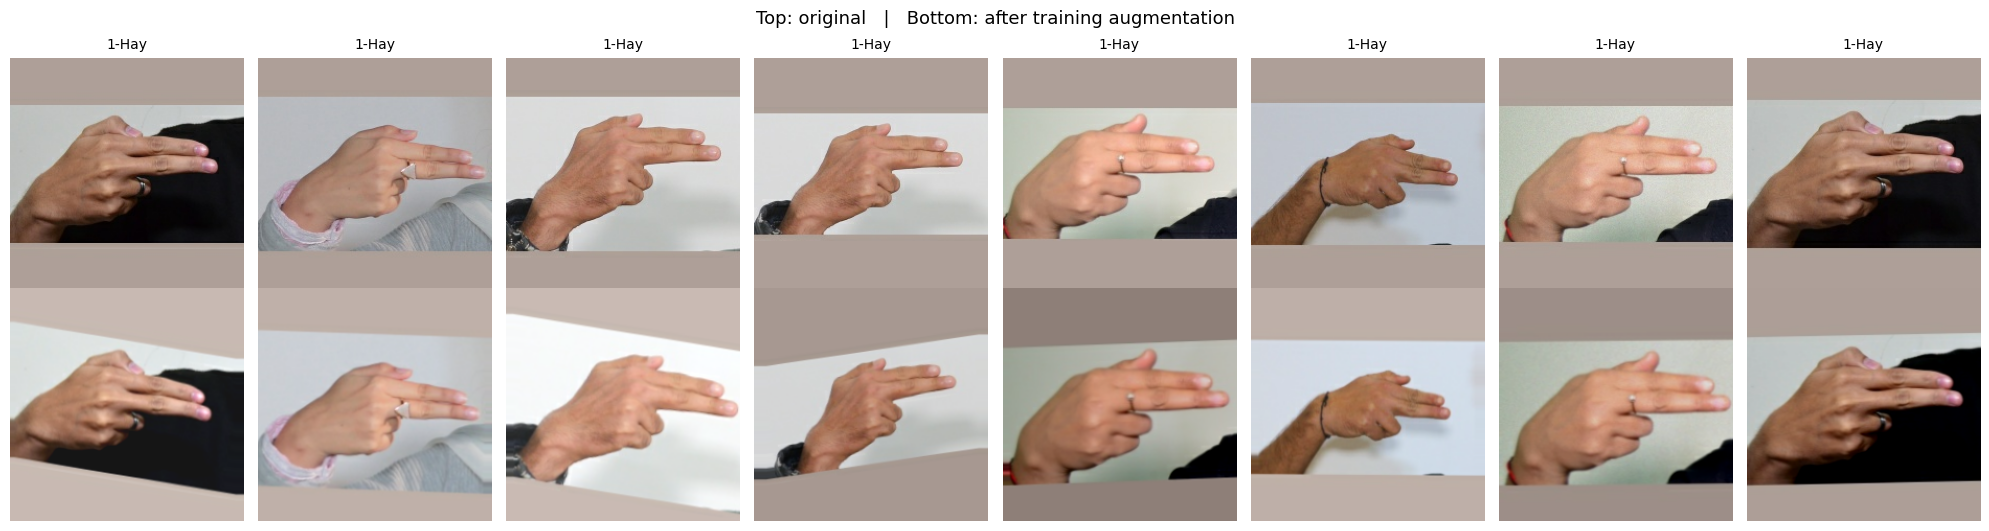

In [8]:
# Visual check: original (top) vs augmented (bottom) for the same 8 validation images
xb, yb = next(iter(make_static_ds('val', norm='efficientnet', batch=8)))
xa = augment(xb, training=True)
fig, axes = plt.subplots(2, 8, figsize=(20, 5.4))
for i in range(8):
    axes[0, i].imshow(xb[i].numpy().astype('uint8')); axes[0, i].set_title(id2label[int(yb[i])], fontsize=10); axes[0, i].axis('off')
    axes[1, i].imshow(np.clip(xa[i].numpy(), 0, 255).astype('uint8')); axes[1, i].axis('off')
axes[0, 0].set_ylabel('original'); fig.suptitle('Top: original   |   Bottom: after training augmentation', fontsize=13)
plt.tight_layout(); plt.savefig(f'{OUT}/p2_01_augmentation_check.png', dpi=130, bbox_inches='tight'); plt.show()

## 4. Dynamic data (landmark sequences)
The array rows follow the order of the videos in `processed_metadata.csv`. Labels are shifted to 0–3 (global ids 36–39 → 0–3).

In [9]:
npz = np.load(f'{WORK}/dynamic_landmarks.npz', allow_pickle=False)
X, M, y_glob, split_arr, files = npz['X'], npz['mask'], npz['y'], npz['split'], npz['files']
assert (dyn['npz_index'].values == np.arange(len(dyn))).all() and (dyn['rel_path'].values == files).all(), 'npz rows do not match metadata'
y_dyn = (y_glob - len(STATIC)).astype('int32')
assert set(np.unique(y_dyn)) == set(range(len(DYNAMIC)))

DYN = {s: (X[split_arr == s], y_dyn[split_arr == s], M[split_arr == s]) for s in ['train', 'val', 'test']}
print('X:', X.shape, X.dtype, '| NaNs:', int(np.isnan(X).sum()), '| value range:', float(X.min()), 'to', float(X.max()))
for s, (xs, ys, ms) in DYN.items():
    print(f"{s:5s} X={xs.shape} class counts={dict(zip(DYNAMIC, np.bincount(ys, minlength=len(DYNAMIC))))} detected-frame rate={ms.mean():.3f}")
print('Dynamic class weights:', {DYNAMIC[k]: v for k, v in dyn_cw.items()})

X: (393, 88, 63) float32 | NaNs: 0 | value range: -2.30810546875 to 1.0
train X=(275, 88, 63) class counts={'2-Hay': np.int64(61), 'Alifmad': np.int64(74), 'Aray': np.int64(71), 'Jeem': np.int64(69)} detected-frame rate=0.970
val   X=(59, 88, 63) class counts={'2-Hay': np.int64(13), 'Alifmad': np.int64(15), 'Aray': np.int64(16), 'Jeem': np.int64(15)} detected-frame rate=0.971
test  X=(59, 88, 63) class counts={'2-Hay': np.int64(13), 'Alifmad': np.int64(16), 'Aray': np.int64(15), 'Jeem': np.int64(15)} detected-frame rate=0.976
Dynamic class weights: {'2-Hay': 1.127, 'Alifmad': 0.9291, 'Aray': 0.9683, 'Jeem': 0.9964}


In [10]:
def augment_sequence(seq, rng, noise=0.02, scale=(0.9, 1.1), max_shift=4):
    # Seq: (T, 63) normalized landmarks. Small noise, uniform rescale, and a small time shift (zeros stay zeros).
    out = seq.copy(); valid = np.abs(out).sum(1) > 0
    out[valid] = out[valid] * rng.uniform(*scale) + rng.normal(0, noise, out[valid].shape)
    sh = int(rng.integers(-max_shift, max_shift + 1))
    return np.roll(out, sh, axis=0)

rng = np.random.default_rng(SEED)
a = augment_sequence(DYN['train'][0][0], rng)
assert a.shape == DYN['train'][0][0].shape; print('augment_sequence OK ->', a.shape)

augment_sequence OK -> (88, 63)


In [11]:
def hdr(t): print('\n' + '=' * 70 + f'\n{t}\n' + '=' * 70)
hdr('Environment'); print('TensorFlow', tf.__version__, '| GPUs:', [g.name for g in gpus])
hdr('Static data'); print('Images per split:', imgs['split'].value_counts().to_dict())
print('Originals per split:', imgs[~imgs['is_generated']]['split'].value_counts().to_dict())
print('Batch shape:', tuple(x.shape), '| batch size:', BATCH, '| loading speed:', round(speed), 'images/s')
hdr('Dynamic data')
for s, (xs, ys, ms) in DYN.items(): print(s, xs.shape, np.bincount(ys, minlength=len(DYNAMIC)).tolist())
hdr('Files to download from /content/results'); print(sorted(os.listdir(OUT)))


Environment
TensorFlow 2.21.0 | GPUs: ['/physical_device:GPU:0']

Static data
Images per split: {'train': 15062, 'test': 3238, 'val': 3060}
Originals per split: {'train': 2028, 'val': 439, 'test': 430}
Batch shape: (64, 224, 224, 3) | batch size: 64 | loading speed: 62 images/s

Dynamic data
train (275, 88, 63) [61, 74, 71, 69]
val (59, 88, 63) [13, 15, 16, 15]
test (59, 88, 63) [13, 16, 15, 15]

Files to download from /content/results
['p2_01_augmentation_check.png']
